## Importo posibles librerías

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

## ANÁLISIS 3 - Análisis del rendimiento según su contexto socio-económico


La variable "lunch" podemos utilizarla como indicador indirecto del contexto socio-económico, por tanto, nos podemos plantear si existe una relación entre el contexto socioeconómico del estudiante y su rendimiento académico.

In [2]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

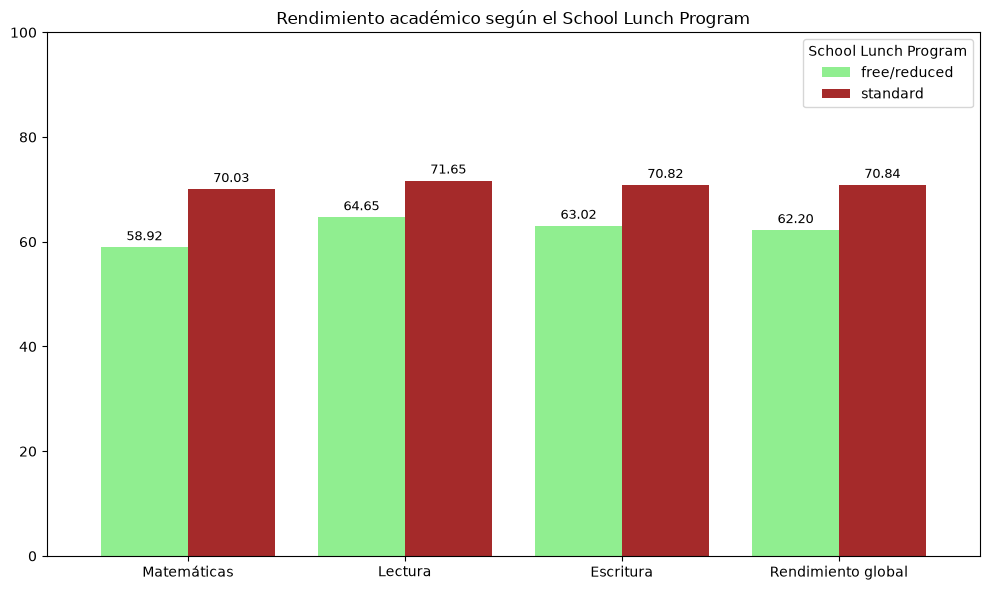

In [3]:
rendimiento_lunch = sp.groupby("lunch")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_lunch = rendimiento_lunch.T #trasponer los datos para poder sacar el gráfico que quiero

rend = rendimiento_lunch.plot(kind="bar", figsize=(10, 6), width=0.8, color=["lightgreen", "brown"])

plt.title("Rendimiento académico según el School Lunch Program")
plt.xticks(ticks=range(4), labels=["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)

for container in rend.containers:
    rend.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.ylim(0, 100)
plt.legend(title="School Lunch Program")

plt.tight_layout()

plt.savefig("../img/Grafico_3_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

El gráfico evidencia que existen diferencias en el rendimiento de las 3 comptencias entre los alumnos que, en el Programa de Comidas, tienen una tarifa estándar frente a los que tienen un tarifa reducida o subencionada.

Sobre todo en "Matemáticas", donde la diferencia es más notable.

Pero, ¿Son estadísticamente significativas? Para ello vamos a usar la libreria "scipy" con el módulo "stats" y concretamemte la función "ttest_ind", que corresponde a la prueba t-Student para muestras independientes:


In [4]:
variables = ["math_score", "reading_score", "writing_score", "global_score"]

for variable in variables:

    standard = sp[sp["lunch"] == "standard"][variable]
    free_reduced = sp[sp["lunch"] == "free/reduced"][variable]

    t, p = ttest_ind(standard, free_reduced, equal_var=False)

    print("\n", variable)
    print("Estadístico t:", round(t, 4))
    print("p-valor:", round(p, 4))

    if p < 0.05:
        print("Existe una diferencia estadísticamente significativa")
    else:
        print("No existe una diferencia estadísticamente significativa")


 math_score
Estadístico t: 11.4841
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 reading_score
Estadístico t: 7.2926
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 writing_score
Estadístico t: 7.8409
p-valor: 0.0
Existe una diferencia estadísticamente significativa

 global_score
Estadístico t: 9.3232
p-valor: 0.0
Existe una diferencia estadísticamente significativa


Los resultados confirman que las diferencias son estadísticamente significativas. Vemos que los estudiantes 
con tarifa estándar obtienen resultados significativamente mejores que los que tienen tarifa reducida o subencionada. 

Si entendemos esta variable como una aproximación al nivel socio-económico de la familia, observamos que el nivel socio-económico familiar influye en los resultados académicos.